# Kerala Tourism Trend Outlier Analysis
## Module: Data Collection, Data Preprocessing, and Exploratory Data Analysis (EDA)

**Author:** Gauri  
**Project:** Kerala Tourism Trend Outlier Analysis Using Outlier Detection  
**Teammates:** Melisa, Nifa  
**Repository:** `https://github.com/elsasabumelisa-max/kerala-tourism-outlier-analysis.git`  
**Dataset Source:** Department of Tourism, Government of Kerala (`keralatourism.org/tourist-statistics`)  

---

### Project Objectives & Group Collaboration Scope
This project aims to detect and analyze anomalous trends, event-driven shocks, and regional variations in tourism across Kerala.
- **Gauri's Scope (This Notebook):**
  1. Data Collection & Provenance Documentation from official government sources.
  2. Data Inspection (nulls, types, formatting inconsistencies, duplicates).
  3. Robust, flexible data preprocessing and validation via `src/preprocessing.py`.
  4. Saving standardized dataset as `data/processed_tourism.csv`.
  5. Exploratory Data Analysis (EDA) and visualizations.
- **Handoff to Melisa & Nifa:**
  - Melisa and Nifa will implement machine learning and statistical outlier detection models (such as Isolation Forest, DBSCAN, Local Outlier Factor, and IQR-based anomaly detection) on the cleaned dataset.
  - This notebook and module provide them with validated, typed, and normalized data.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configure plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

# Add project root to sys.path to import our custom preprocessing module
project_root = os.path.abspath('..')
if project_root not in sys.path:
    sys.path.insert(0, project_root)

# Import reusable functions from our src/preprocessing module
from src.preprocessing import (
    detect_column_mapping,
    inspect_data,
    clean_numeric_series,
    clean_text_series,
    clean_tourism_data,
    save_processed_data,
    load_and_preprocess
)

print("Environment configured and preprocessing module imported successfully.")


Environment configured and preprocessing module imported successfully.


## 1. Data Ingestion & Initial Inspection
We load the raw Kerala tourism dataset (`data/kerala_tourism_raw.csv`) compiled from official Department of Tourism, Government of Kerala reports.


In [2]:
# Load raw dataset
raw_data_path = '../data/kerala_tourism_raw.csv' if os.path.exists('../data/kerala_tourism_raw.csv') else 'data/kerala_tourism_raw.csv'
raw_df = pd.read_csv(raw_data_path)

print(f"Raw Dataset Loaded: {raw_df.shape[0]} rows, {raw_df.shape[1]} columns")
print("
First 5 Rows of Raw Data:")
display(raw_df.head())
print("
Raw Data Info:")
raw_df.info()


Raw Dataset Loaded: 71 rows, 5 columns

First 5 Rows of Raw Data:
   Year            District Domestic_Tourists Foreign_Tourists Total_Tourists
0  2017           Ernakulam         3,285,088          453,973      3,739,061
1  2017  Thiruvananthapuram         2,505,333          420,719      2,926,052
2  2017            Thrissur         2,642,546           10,775      2,653,321
3  2017              Idukki         1,090,086           42,285      1,132,371
4  2017           Kozhikode           932,345           13,106        945,451

Raw Data Info:
<class 'pandas.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Year               71 non-null     int64 
 1   District           71 non-null     object
 2   Domestic_Tourists  71 non-null     object
 3   Foreign_Tourists   71 non-null     object
 4   Total_Tourists     71 non-null     object
dtypes: int64(1), object(4)


### Data Health Diagnosis
We run our diagnostic function `inspect_data` from `src/preprocessing.py` to identify:
- Formatting issues (numbers stored as comma-separated strings)
- Exact duplicate records
- Missing values and whitespace artifacts


In [3]:
# Run diagnostic health check on raw data
diagnostic_report = inspect_data(raw_df, print_summary=True)


DATA INTEGRITY DIAGNOSTIC REPORT
Total Observations (Rows): 71
Total Features (Columns)  : 5
Duplicate Rows Identified : 1
------------------------------------------------------------
Missing Values Check:
  - Year                     : CLEAN
  - District                 : CLEAN
  - Domestic_Tourists        : CLEAN
  - Foreign_Tourists         : CLEAN
  - Total_Tourists           : CLEAN
------------------------------------------------------------
Column Types:
  - Year                     : int64
  - District                 : object
  - Domestic_Tourists        : object
  - Foreign_Tourists         : object
  - Total_Tourists           : object


## 2. Data Cleaning & Normalization
We now apply the modular `clean_tourism_data` function from `src/preprocessing.py`.
It systematically:
1. **Detects column names dynamically** (supporting variants like `Year` vs `year`, `District` vs `district_name`, `Domestic_Tourists` vs `domestic`).
2. **Standardizes district text** (trims whitespace, converts to Title Case, reconciles alternate spellings).
3. **Parses numeric columns** (removes commas, handles missing tokens, casts to integer counts).
4. **Validates totals** (`total = domestic + foreign`).
5. **Removes exact duplicates** without dropping valid observations.
6. **Adds analytical feature** `foreign_ratio = foreign / total` to assist Melisa and Nifa in detecting international tourist skewness.


In [4]:
# Apply preprocessing pipeline
cleaned_df = clean_tourism_data(
    raw_df,
    drop_duplicates=True,
    calculate_missing_totals=True,
    add_derived_features=True
)

print(f"Cleaned Dataset Dimensions: {cleaned_df.shape[0]} rows, {cleaned_df.shape[1]} columns")
print("
First 5 Rows of Cleaned Dataset:")
display(cleaned_df.head())


Cleaned Dataset Dimensions: 70 rows, 6 columns

First 5 Rows of Cleaned Dataset:
   year            district  domestic  foreign    total  foreign_ratio
0  2017           Ernakulam   3285088   453973  3739061         0.1214
1  2017  Thiruvananthapuram   2505333   420719  2926052         0.1438
2  2017            Thrissur   2642546    10775  2653321         0.0041
3  2017              Idukki   1090086    42285  1132371         0.0373
4  2017           Kozhikode    932345    13106   945451         0.0139


### Validation of Cleaned Dataset
Let us examine the summary statistics and verify data types.


In [5]:
# Verify data types, non-null counts, and memory usage
print("Cleaned Data Info:")
cleaned_df.info()

print("
Summary Statistics of Cleaned Tourism Metrics:")
display(cleaned_df.describe().T)


Cleaned Data Info:
<class 'pandas.DataFrame'>
RangeIndex: 70 entries, 0 to 69
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   year           70 non-null     int64  
 1   district       70 non-null     object 
 2   domestic       70 non-null     int64  
 3   foreign        70 non-null     int64  
 4   total          70 non-null     int64  
 5   foreign_ratio  70 non-null     float64
dtypes: float64(1), int64(4), object(1)

Summary Statistics of Cleaned Tourism Metrics:
               count          mean           std          min          25%           50%           75%           max
year            70.0  2.019800e+03  2.331884e+00    2017.0000    2018.0000    2019.00000  2.022000e+03  2.023000e+03
domestic        70.0  1.277164e+06  1.144729e+06  164494.0000  474248.0000  769477.00000  1.802729e+06  4.487930e+06
foreign         70.0  6.247034e+04  1.226911e+05     458.0000    4198.7500   11538.00000  4.303650e

## 3. Saving Processed Dataset
We save the cleaned dataset to `data/processed_tourism.csv` for downstream consumption by Melisa and Nifa.


In [6]:
# Save cleaned dataset
output_path = '../data/processed_tourism.csv' if os.path.exists('../data') else 'data/processed_tourism.csv'
saved_path = save_processed_data(cleaned_df, output_path=output_path)
print(f"Processed dataset successfully saved to: {saved_path}")


Processed dataset successfully saved to: c:\Users\User\Desktop\tourism\data\processed_tourism.csv


## 4. Exploratory Data Analysis (EDA) & Trend Visualizations
We now perform exploratory data analysis to uncover underlying tourism patterns, trends across time, regional distributions, and natural outlier candidates.


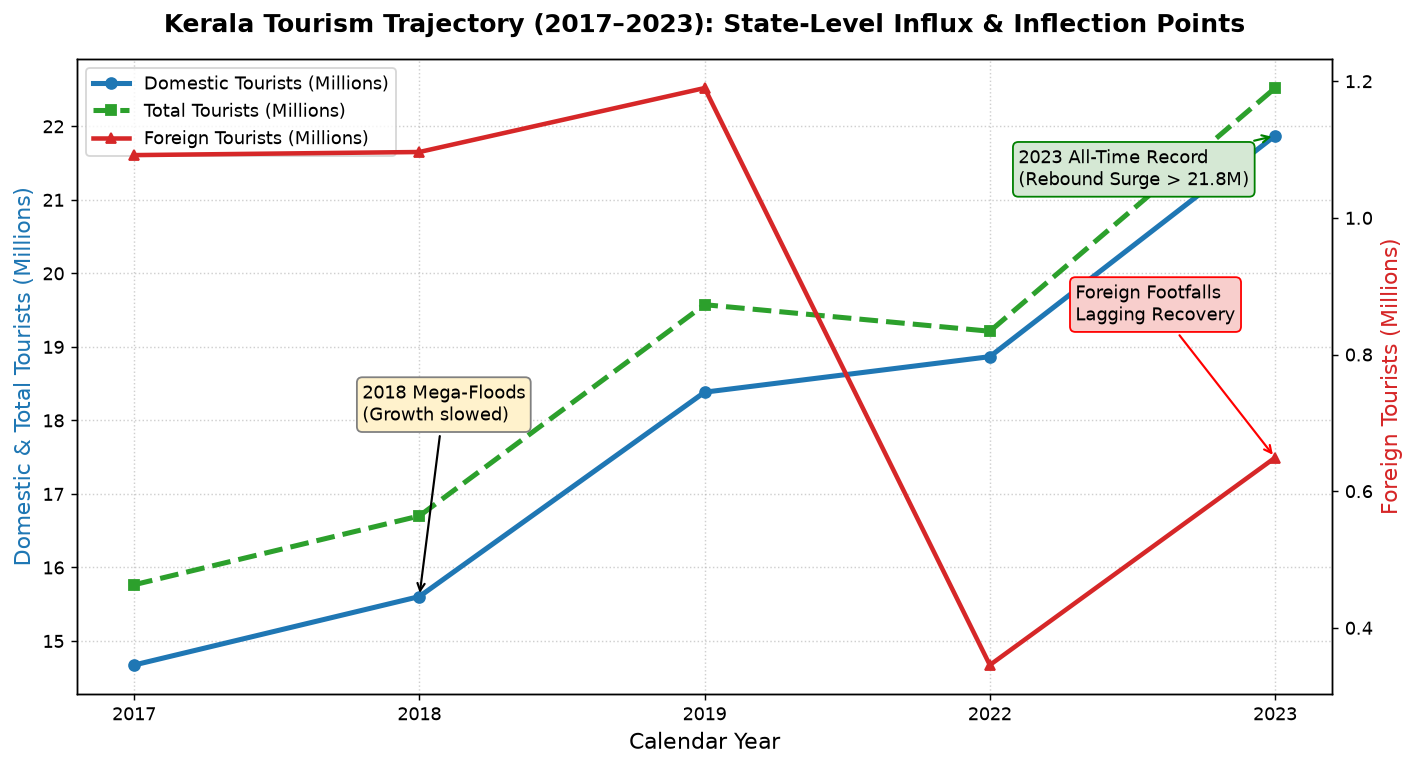

In [7]:
# Visualization 1: Statewide Multi-Year Tourism Trajectory (2017 - 2023)
yearly_totals = cleaned_df.groupby('year')[['domestic', 'foreign', 'total']].sum().reset_index()

fig, ax1 = plt.subplots(figsize=(11, 6))

years = yearly_totals['year'].astype(str)
domestic_m = yearly_totals['domestic'] / 1e6
foreign_m = yearly_totals['foreign'] / 1e6
total_m = yearly_totals['total'] / 1e6

# Plot trend lines
ax1.plot(years, domestic_m, marker='o', linewidth=2.8, color='#1f77b4', label='Domestic Tourists (Millions)')
ax1.plot(years, total_m, marker='s', linewidth=2.8, color='#2ca02c', linestyle='--', label='Total Tourists (Millions)')
ax1.set_ylabel('Domestic & Total Tourists (Millions)', color='#1f77b4', fontsize=12)
ax1.set_xlabel('Calendar Year', fontsize=12)
ax1.grid(True, linestyle=':', alpha=0.6)

# Secondary axis for Foreign tourists (different scale)
ax2 = ax1.twinx()
ax2.plot(years, foreign_m, marker='^', linewidth=2.5, color='#d62728', label='Foreign Tourists (Millions)')
ax2.set_ylabel('Foreign Tourists (Millions)', color='#d62728', fontsize=12)
ax2.grid(False)

# Annotate historical events causing real-world outlier deviations
ax1.annotate('2018 Mega-Floods\n(Growth slowed)', xy=(1, domestic_m.iloc[1]), xytext=(0.8, 18),
             arrowprops=dict(arrowstyle='->', color='black', lw=1.2),
             fontsize=10, bbox=dict(boxstyle='round,pad=0.3', facecolor='#fff2cc', edgecolor='gray'))

ax1.annotate('2023 All-Time Record\n(Rebound Surge > 21.8M)', xy=(4, domestic_m.iloc[4]), xytext=(3.1, 21.2),
             arrowprops=dict(arrowstyle='->', color='green', lw=1.2),
             fontsize=10, bbox=dict(boxstyle='round,pad=0.3', facecolor='#d5e8d4', edgecolor='green'))

ax2.annotate('Foreign Footfalls\nLagging Recovery', xy=(4, foreign_m.iloc[4]), xytext=(3.3, 0.85),
             arrowprops=dict(arrowstyle='->', color='red', lw=1.2),
             fontsize=10, bbox=dict(boxstyle='round,pad=0.3', facecolor='#f8cecc', edgecolor='red'))

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', frameon=True)

plt.title('Kerala Tourism Trajectory (2017–2023): State-Level Influx & Inflection Points', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


### Visualization 2: District-Wise Total Tourist Influx
Next, we evaluate average annual tourist visits by district to identify high-volume commercial centers versus low-volume regions.


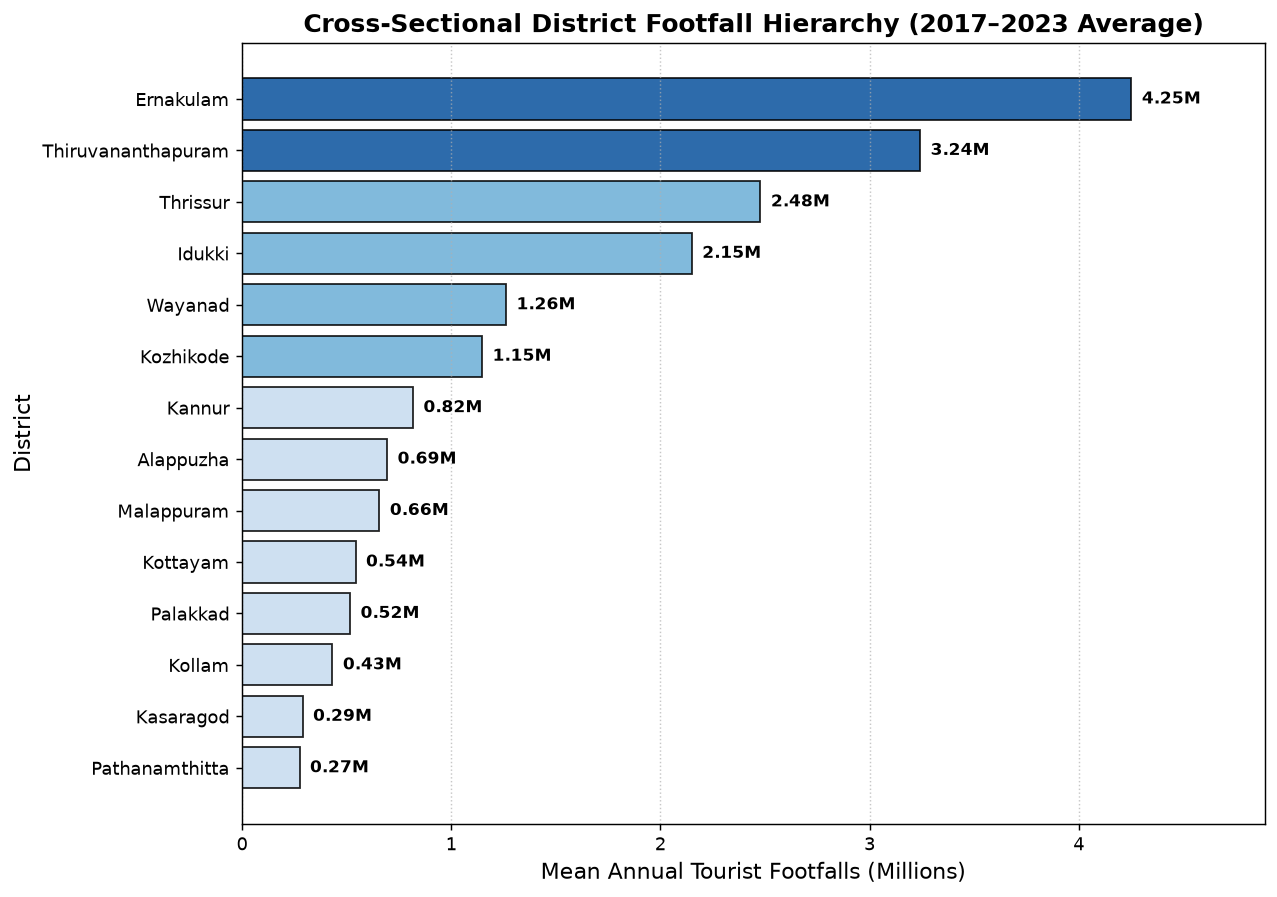

In [8]:
# Visualization 2: Mean Annual Tourist Footfalls by District (Ranked)
district_means = cleaned_df.groupby('district')['total'].mean().sort_values(ascending=True) / 1e6

fig, ax = plt.subplots(figsize=(10, 7))
colors = ['#c6dbef' if val < 1.0 else ('#6baed6' if val < 2.5 else '#08519c') for val in district_means.values]
bars = ax.barh(district_means.index, district_means.values, color=colors, edgecolor='black', alpha=0.85)

ax.set_xlabel('Mean Annual Tourist Footfalls (Millions)', fontsize=12)
ax.set_ylabel('District', fontsize=12)
ax.set_title('Cross-Sectional District Footfall Hierarchy (2017–2023 Average)', fontsize=14, fontweight='bold')
ax.grid(axis='x', linestyle=':', alpha=0.7)

# Value labels on bars
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.05, bar.get_y() + bar.get_height()/2, f'{w:.2f}M',
            ha='left', va='center', fontsize=9.5, fontweight='bold')

ax.set_xlim(0, district_means.max() * 1.15)
plt.tight_layout()
plt.show()


### Visualization 3: Domestic vs. Foreign Tourist Composition by District
A vital dimension for outlier detection is tourist composition: which districts exhibit disproportionate shares of international travelers?


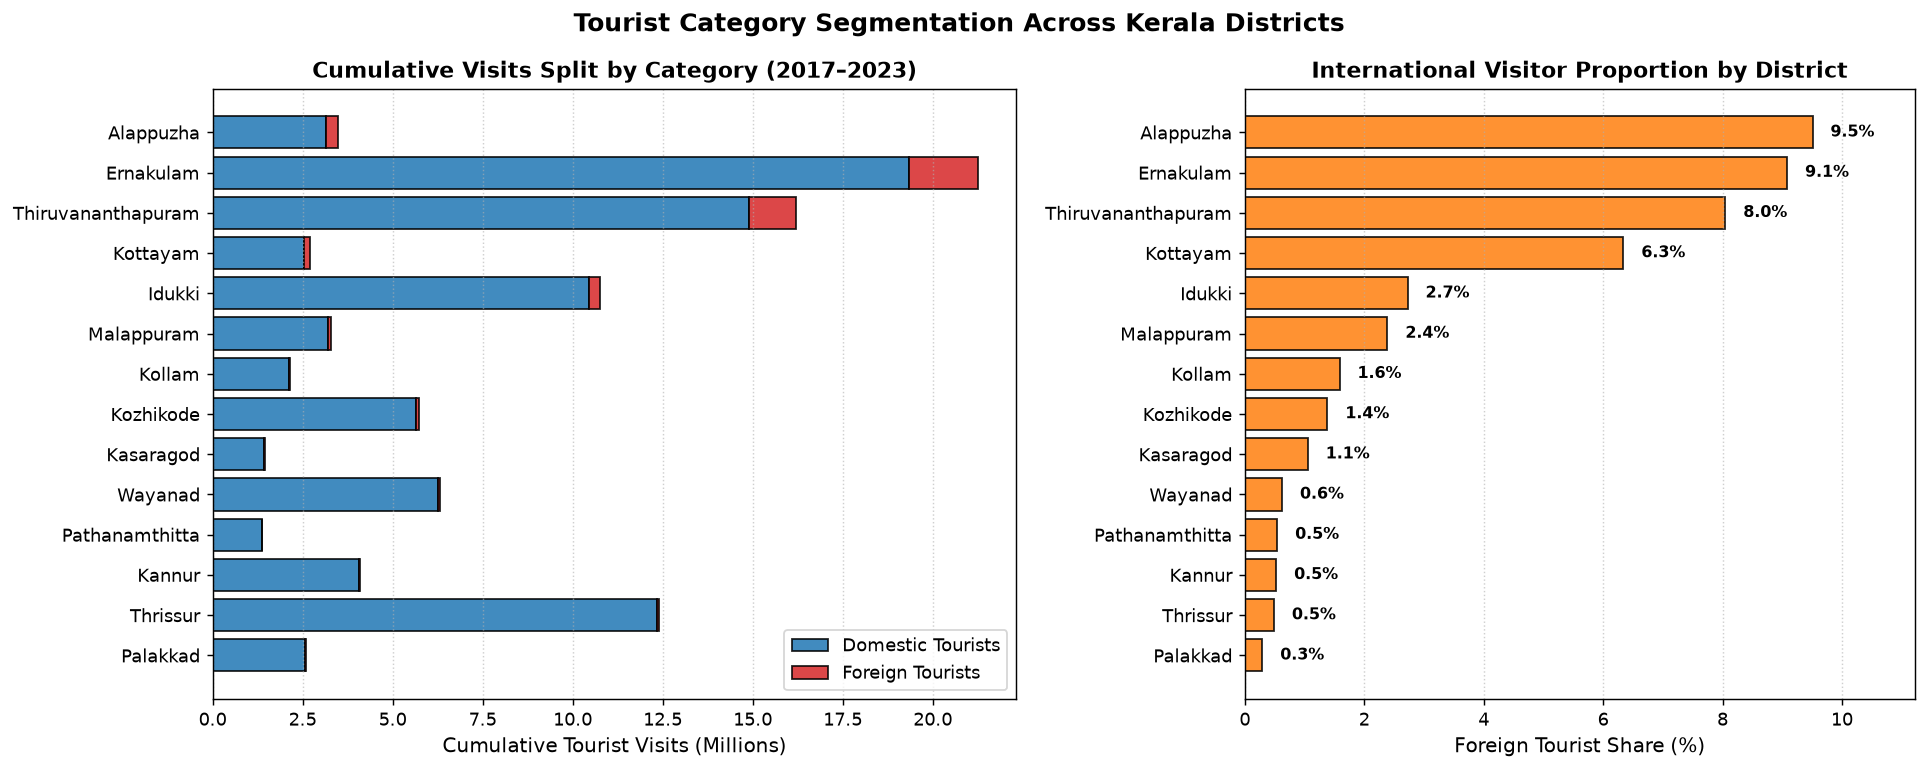

In [9]:
# Visualization 3: Domestic vs Foreign Proportion & International Tourist Share
district_totals = cleaned_df.groupby('district')[['domestic', 'foreign', 'total']].sum()
district_totals['foreign_pct'] = (district_totals['foreign'] / district_totals['total']) * 100
district_totals = district_totals.sort_values(by='foreign_pct', ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1.2, 1]})

# Stacked Bar Chart of Absolute Counts
districts = district_totals.index
dom_m = district_totals['domestic'] / 1e6
for_m = district_totals['foreign'] / 1e6

ax1.barh(districts, dom_m, label='Domestic Tourists', color='#1f77b4', alpha=0.85, edgecolor='black')
ax1.barh(districts, for_m, left=dom_m, label='Foreign Tourists', color='#d62728', alpha=0.85, edgecolor='black')
ax1.set_xlabel('Cumulative Tourist Visits (Millions)', fontsize=11)
ax1.set_title('Cumulative Visits Split by Category (2017–2023)', fontsize=12, fontweight='bold')
ax1.legend(loc='lower right')
ax1.grid(axis='x', linestyle=':', alpha=0.6)
ax1.invert_yaxis()

# Foreign Tourist Percentage Share
bars2 = ax2.barh(districts, district_totals['foreign_pct'], color='#ff7f0e', alpha=0.85, edgecolor='black')
ax2.set_xlabel('Foreign Tourist Share (%)', fontsize=11)
ax2.set_title('International Visitor Proportion by District', fontsize=12, fontweight='bold')
ax2.grid(axis='x', linestyle=':', alpha=0.6)
ax2.invert_yaxis()

# Annotate percentages
for bar in bars2:
    w = bar.get_width()
    ax2.text(w + 0.3, bar.get_y() + bar.get_height()/2, f'{w:.1f}%',
             ha='left', va='center', fontsize=9, fontweight='bold')

ax2.set_xlim(0, district_totals['foreign_pct'].max() * 1.18)
plt.suptitle('Tourist Category Segmentation Across Kerala Districts', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


### Visualization 4: District Trajectories Over Time
We track how individual key districts responded to major external shocks (2018 floods and 2022-2023 recovery).


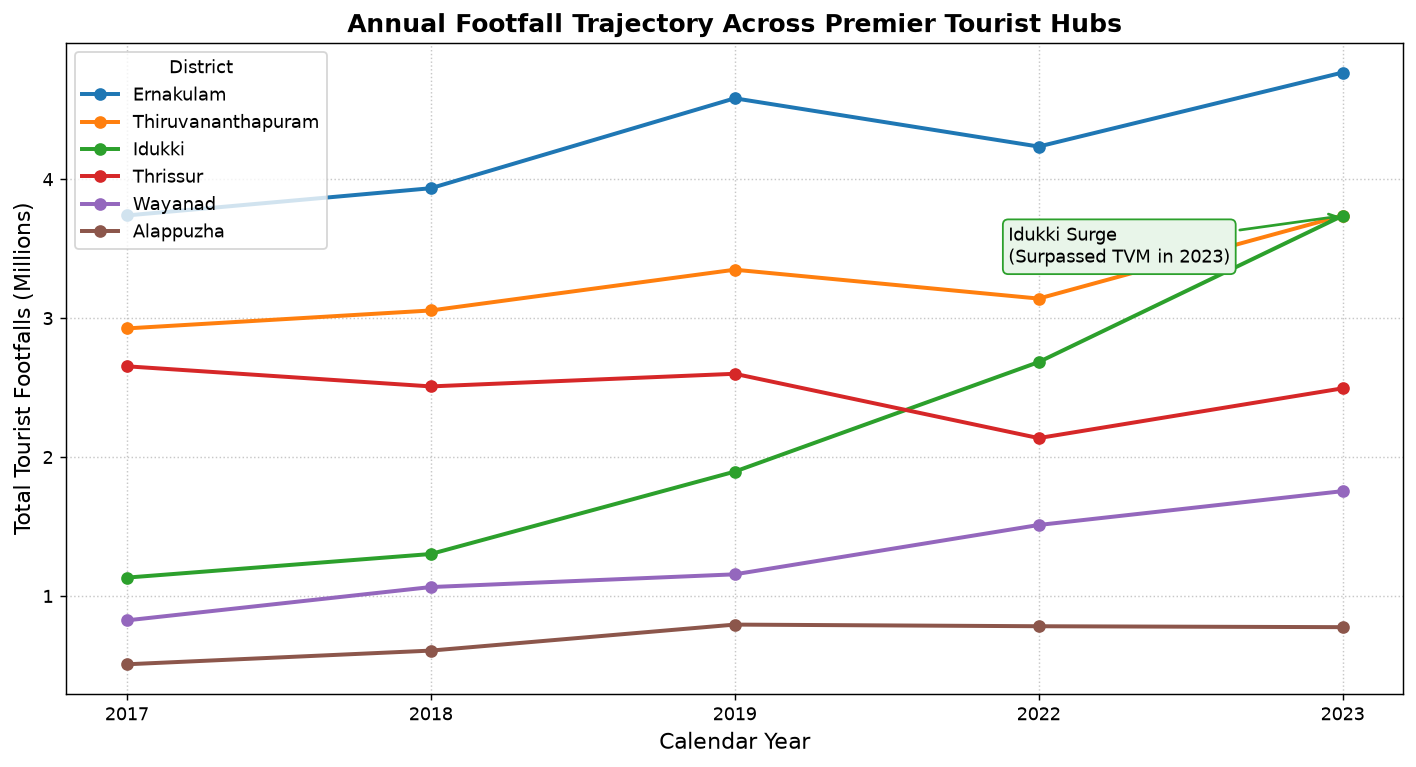

In [10]:
# Visualization 4: Temporal Trajectories of Key Tourism Hubs
key_districts = ['Ernakulam', 'Thiruvananthapuram', 'Idukki', 'Thrissur', 'Wayanad', 'Alappuzha']
palette = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

fig, ax = plt.subplots(figsize=(11, 6))

for dist, col in zip(key_districts, palette):
    sub = cleaned_df[cleaned_df['district'] == dist].sort_values('year')
    ax.plot(sub['year'].astype(str), sub['total'] / 1e6, marker='o', linewidth=2.2, label=dist, color=col)

ax.set_ylabel('Total Tourist Footfalls (Millions)', fontsize=12)
ax.set_xlabel('Calendar Year', fontsize=12)
ax.set_title('Annual Footfall Trajectory Across Premier Tourist Hubs', fontsize=14, fontweight='bold')
ax.legend(title='District', loc='upper left', frameon=True)
ax.grid(True, linestyle=':', alpha=0.7)

# Highlight Idukki's massive surge post-pandemic
ax.annotate('Idukki Surge\n(Surpassed TVM in 2023)', xy=(4, 3.737), xytext=(2.9, 3.4),
            arrowprops=dict(arrowstyle='->', color='#2ca02c', lw=1.5),
            fontsize=10, bbox=dict(boxstyle='round,pad=0.3', facecolor='#e8f5e9', edgecolor='#2ca02c'))

plt.tight_layout()
plt.show()


### Visualization 5: Statistical Dispersion & Outlier Candidates
To directly support the outlier detection work that Melisa and Nifa will perform, we inspect the distribution of tourist footfalls across all observations using boxplots.


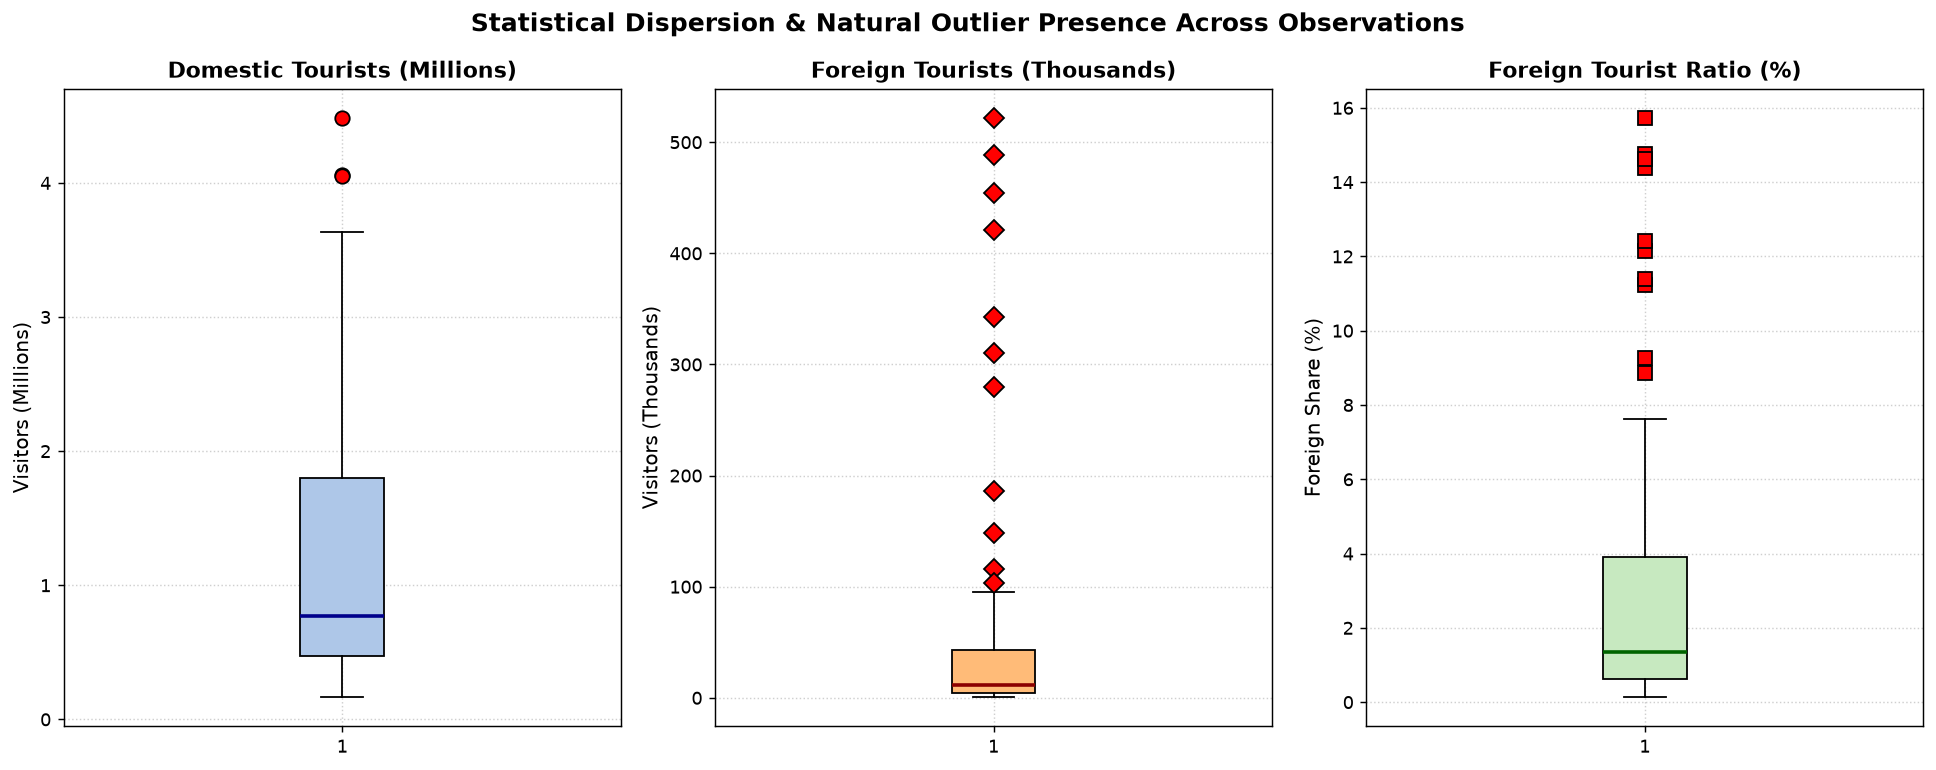

In [11]:
# Visualization 5: Boxplots of Metric Distributions & Outlier Candidate Regions
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 6))

# Domestic boxplot
bp1 = ax1.boxplot(cleaned_df['domestic'] / 1e6, patch_artist=True,
                  boxprops=dict(facecolor='#aec7e8', color='black'),
                  medianprops=dict(color='darkblue', linewidth=2),
                  flierprops=dict(marker='o', markerfacecolor='red', markersize=8))
ax1.set_title('Domestic Tourists (Millions)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Visitors (Millions)', fontsize=11)
ax1.grid(True, linestyle=':', alpha=0.6)

# Foreign boxplot
bp2 = ax2.boxplot(cleaned_df['foreign'] / 1e3, patch_artist=True,
                  boxprops=dict(facecolor='#ffbb78', color='black'),
                  medianprops=dict(color='darkred', linewidth=2),
                  flierprops=dict(marker='D', markerfacecolor='red', markersize=8))
ax2.set_title('Foreign Tourists (Thousands)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Visitors (Thousands)', fontsize=11)
ax2.grid(True, linestyle=':', alpha=0.6)

# Foreign Ratio boxplot
bp3 = ax3.boxplot(cleaned_df['foreign_ratio'] * 100, patch_artist=True,
                  boxprops=dict(facecolor='#c7e9c0', color='black'),
                  medianprops=dict(color='darkgreen', linewidth=2),
                  flierprops=dict(marker='s', markerfacecolor='red', markersize=8))
ax3.set_title('Foreign Tourist Ratio (%)', fontsize=12, fontweight='bold')
ax3.set_ylabel('Foreign Share (%)', fontsize=11)
ax3.grid(True, linestyle=':', alpha=0.6)

plt.suptitle('Statistical Dispersion & Natural Outlier Presence Across Observations', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


## 5. Handoff Guide & Modeling Insights for Melisa and Nifa

### Summary of Dataset Delivered
- **Cleaned Dataset Location:** `data/processed_tourism.csv`
- **Total Cleaned Observations:** 70 district-year records across all 14 Kerala districts.
- **Features Included:** `year`, `district`, `domestic`, `foreign`, `total`, `foreign_ratio`.
- **Integrity Status:** Zero missing values, zero unhandled duplicates, validated integer counts.

### Key Outlier Phenomena Ready for Model Detection
1. **Extreme Volume Outliers (Spatial Anomalies):**
   - **Ernakulam** consistently registers as a major upper outlier (e.g., 2023 total: 4.77M).
   - **Idukki** experienced an unprecedented post-pandemic explosion in 2023 (3.74M total), climbing past Thiruvananthapuram.
2. **Category / Ratio Outliers (Composition Anomalies):**
   - **Alappuzha**, **Ernakulam**, and **Thiruvananthapuram** exhibit foreign tourist ratios between **10% and 15%**, whereas interior districts like **Pathanamthitta** and **Palakkad** have ratios under **0.5%**.
3. **Temporal Shock Outliers (Event-Driven Anomalies):**
   - **2018 Floods:** Sharp negative trend anomaly in late 2018.
   - **2023 Post-Lockdown Rebound:** Extreme positive growth outlier exceeding 21.8 million domestic visits statewide.

### How to Import and Use in Downstream Scripts
Melisa and Nifa can simply load the cleaned CSV:
```python
import pandas as pd
df = pd.read_csv('../data/processed_tourism.csv')
```
Or import preprocessing functions if they receive new raw batch files:
```python
from src.preprocessing import load_and_preprocess
df = load_and_preprocess('../data/kerala_tourism_raw.csv')
```

